VST a nivel oracion 
1. Secuencia de frames (t,c,96,96)
2. CNN - feature extreactor - reducir dimensiones y preservar T 
3. GRU/LSTM - modelado temporal 
4. Clasificación + CTC : 71 clases de caracteres, incluido blank 

In [1]:
import json
import math
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import pyarrow

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

# Reproducibilidad
SEED = 42

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Configuración
CLIPS_DIR = Path(r"D:\ViSpeR\clips")
METADATA_PATH = CLIPS_DIR / "metadata.json"

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

INPUT_CHANNELS = 3  # Provisional: mas adelante enfrentamos a grayscale
VOCAB_SIZE = 71     # 70 caracteres + CTC blank

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA disponible:", torch.cuda.is_available())
print("Device:", DEVICE)
print("Metadata existe:", METADATA_PATH.exists())
print("Vocabulario:", VOCAB_SIZE)

PyTorch: 2.6.0+cu126
CUDA disponible: True
Device: cuda
Metadata existe: True
Vocabulario: 71


In [2]:
from collections import Counter
from pathlib import Path

with open(METADATA_PATH, "r", encoding="utf-8") as f:
    metadata = json.load(f)

all_text = "".join(
    info["label"] for info in metadata.values()
)

char_counts = Counter(all_text)

characters = sorted(char_counts.keys())

print(f"Cantidad de caracteres distintos: {len(characters)}")
print(f"Cantidad total con CTC blank: {len(characters) + 1}")
print("\nVocabulario:")
for i, char in enumerate(characters, start=1):
    print(f"{i:2} | {repr(char):8} | frecuencia: {char_counts[char]}")

print("\nCTC blank: 0")

Cantidad de caracteres distintos: 70
Cantidad total con CTC blank: 71

Vocabulario:
 1 | ' '      | frecuencia: 16524
 2 | '0'      | frecuencia: 57
 3 | '1'      | frecuencia: 29
 4 | '2'      | frecuencia: 29
 5 | '3'      | frecuencia: 14
 6 | '4'      | frecuencia: 11
 7 | '5'      | frecuencia: 18
 8 | '6'      | frecuencia: 3
 9 | '7'      | frecuencia: 2
10 | '8'      | frecuencia: 11
11 | '9'      | frecuencia: 8
12 | 'A'      | frecuencia: 72
13 | 'B'      | frecuencia: 25
14 | 'C'      | frecuencia: 97
15 | 'D'      | frecuencia: 29
16 | 'E'      | frecuencia: 139
17 | 'F'      | frecuencia: 12
18 | 'G'      | frecuencia: 17
19 | 'H'      | frecuencia: 26
20 | 'I'      | frecuencia: 15
21 | 'J'      | frecuencia: 6
22 | 'K'      | frecuencia: 10
23 | 'L'      | frecuencia: 56
24 | 'M'      | frecuencia: 51
25 | 'N'      | frecuencia: 47
26 | 'O'      | frecuencia: 18
27 | 'P'      | frecuencia: 86
28 | 'Q'      | frecuencia: 27
29 | 'R'      | frecuencia: 18
30 | 'S'      | f

In [3]:
IMAGE_MODE = "rgb"
INPUT_CHANNELS = 3

IMAGE_HEIGHT = 96
IMAGE_WIDTH = 96

BLANK_IDX = 0
VOCAB_SIZE = len(characters) + 1

print("Modo de imagen:", IMAGE_MODE)
print("Canales de entrada:", INPUT_CHANNELS)
print("Resolución:", IMAGE_HEIGHT, "x", IMAGE_WIDTH)
print("Tamaño del vocabulario:", VOCAB_SIZE)

Modo de imagen: rgb
Canales de entrada: 3
Resolución: 96 x 96
Tamaño del vocabulario: 71


#DATA

In [4]:
DATA_DIR = Path("data")

clips_df = pd.read_parquet(DATA_DIR / "clips_metadata.parquet")
clips_df["path"] = clips_df["path"].apply(Path)

with open(DATA_DIR / "vocabulary.json", "r", encoding="utf-8") as f:
    char_to_idx = json.load(f)

idx_to_char = {
    int(idx): char
    for char, idx in char_to_idx.items()
}

BLANK_IDX = 0
VOCAB_SIZE = len(char_to_idx) + 1

print("Clips:", len(clips_df))
print("Vocabulario:", VOCAB_SIZE)
print("Primer registro:")
display(clips_df.head(1))

Clips: 1304
Vocabulario: 71
Primer registro:


,path,label,frames,ctc_min_frames,repeated_pairs,temporal_margin,min_temporal_ratio,duration_seconds,words_per_second,video_id,is_ctc_problematic,frames_after_x1,margin_after_x1,frames_after_x2,margin_after_x2,frames_after_x3,margin_after_x3,frames_after_x4,margin_after_x4
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108,41,2,67,0.37963,4.32,1.388889,0YEeb-WLF2w,False,108,67,54,13,36,-5,27,-14


In [5]:
class ViSpeRDataset(Dataset):
    def __init__(self, dataframe):
        self.dataframe = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        row = self.dataframe.iloc[idx]

        cap = cv2.VideoCapture(str(row["path"]))

        if not cap.isOpened():
            raise RuntimeError(f"No se pudo abrir: {row['path']}")

        frames = []

        while True:
            ret, frame = cap.read()

            if not ret:
                break

            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)

        cap.release()

        if not frames:
            raise RuntimeError(f"El clip no contiene frames: {row['path']}")

        video = np.stack(frames).astype(np.float32) / 255.0
        video = torch.from_numpy(video).permute(0, 3, 1, 2)

        target = torch.tensor(
            [char_to_idx[char] for char in str(row["label"])],
            dtype=torch.long
        )

        return {
            "video": video,
            "target": target,
            "input_length": video.shape[0],
            "target_length": target.numel(),
            "text": str(row["label"]),
            "path": str(row["path"])
        }

la STCNN va a procesar grupos de frames simultaneamente (menos mal)
Los videos tienen 3 dim relevantes_> h,w,t
conv3d , cada frame va a observar una secuencia, y va a extraer caract de eso
approx 1 +3(3-1) /(25fps) = 0.28s de contexto local 

In [6]:
class STCNN(nn.Module):
    def __init__(self, in_channels=3):
        super().__init__()

        self.block1 = nn.Sequential(
            nn.Conv3d(
                in_channels, 32,
                kernel_size=(3, 5, 5),
                stride=(1, 2, 2),
                padding=(1, 2, 2)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

        self.block2 = nn.Sequential(
            nn.Conv3d(
                32, 64,
                kernel_size=(3, 5, 5),
                stride=(1, 1, 1),
                padding=(1, 2, 2)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

        self.block3 = nn.Sequential(
            nn.Conv3d(
                64, 96,
                kernel_size=(3, 3, 3),
                stride=(1, 1, 1),
                padding=(1, 1, 1)
            ),
            nn.ReLU(),
            nn.MaxPool3d(
                kernel_size=(1, 2, 2),
                stride=(1, 2, 2)
            ),
            nn.Dropout3d(p=0.5)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        return x

In [36]:
# test ficticio 
model_cnn = STCNN(in_channels=INPUT_CHANNELS)

x = torch.randn(2, 3, 75, 96, 96)

with torch.no_grad():
    features = model_cnn(x)

print("Input:", x.shape)
print("Output:", features.shape)

assert features.shape == (2, 96, 75, 6, 6)

print("Dimensiones verificadas correctamente.")

Input: torch.Size([2, 3, 75, 96, 96])
Output: torch.Size([2, 96, 75, 6, 6])
Dimensiones verificadas correctamente.


### preparar la salida a la recurrente 
$ F = 96 \times 6 \times 6 = 3456 $  

cada frame va a quedar representado por un vector de 3456 características. nothermione,notme,you

In [37]:
# (B, C, T, H, W) -> (T, B, C, H, W)
features = features.permute(2, 0, 1, 3, 4)

# (T, B, C, H, W) -> (T, B, F)
features = features.reshape(
    features.shape[0],
    features.shape[1],
    -1
)

print("Features para la RNN:", features.shape)

assert features.shape == (75, 2, 3456)

Features para la RNN: torch.Size([75, 2, 3456])


In [9]:
class TemporalEncoder(nn.Module):
    def __init__(
        self,
        input_size=3456,
        hidden_size=256,
        num_layers=2,
        rnn_type="gru"
    ):
        super().__init__()

        if rnn_type.lower() == "gru":
            rnn_class = nn.GRU
        elif rnn_type.lower() == "lstm":
            rnn_class = nn.LSTM
        else:
            raise ValueError("rnn_type debe ser 'gru' o 'lstm'")

        self.rnn = rnn_class(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            bidirectional=True,
            batch_first=False
        )

    def forward(self, x, lengths):
        packed = pack_padded_sequence(
            x,
            lengths.cpu(),
            batch_first=False,
            enforce_sorted=False
        )

        packed_output, _ = self.rnn(packed)

        output, _ = pad_packed_sequence(
            packed_output,
            batch_first=False,
            total_length=x.size(0)
        )

        return output

In [10]:
class CharacterClassifier(nn.Module):
    def __init__(self, input_size=512, vocab_size=VOCAB_SIZE):
        super().__init__()
        self.linear = nn.Linear(input_size, vocab_size)

    def forward(self, x):
        return self.linear(x)

#cosillas:
la entrada es lo que devuelve el dataLoader -> $(B,T,C,H,W)$
La salida queda en (T,B,V), que es el formato que quiere CTCLoss

In [11]:
class LipReadingModel(nn.Module):
    def __init__(
        self,
        in_channels=3,
        vocab_size=VOCAB_SIZE,
        hidden_size=256,
        rnn_type="gru"
    ):
        super().__init__()

        self.visual_encoder = STCNN(in_channels=in_channels)

        self.temporal_encoder = TemporalEncoder(
            input_size=96 * 6 * 6,
            hidden_size=hidden_size,
            num_layers=2,
            rnn_type=rnn_type
        )

        self.classifier = CharacterClassifier(
            input_size=hidden_size * 2,
            vocab_size=vocab_size
        )

    def forward(self, x, input_lengths):
        # B,T,C,H,W -> B,C,T,H,W
        x = x.permute(0, 2, 1, 3, 4)

        # Extracción de características espacio-temporales
        x = self.visual_encoder(x)

        # B,C,T,H,W -> T,B,C*H*W
        x = x.permute(2, 0, 1, 3, 4)
        x = x.reshape(x.shape[0], x.shape[1], -1)

        # Modelado temporal respetando las longitudes reales
        x = self.temporal_encoder(x, input_lengths)

        # Clasificación por timestep
        x = self.classifier(x)

        return torch.log_softmax(x, dim=-1)

In [38]:
train_dataset = ViSpeRDataset(clips_df) 

sample = train_dataset[0]

print("Video:", sample["video"].shape)
print("Tipo:", sample["video"].dtype)
print("Rango:", sample["video"].min().item(), sample["video"].max().item())
print("Target:", sample["target"].shape)
print("Texto:", sample["text"])

assert sample["video"].ndim == 4
assert sample["video"].shape[1:] == (3, 96, 96)
assert sample["video"].dtype == torch.float32
assert sample["target"].numel() == len(sample["text"])

print("\nValidación correcta.")

Video: torch.Size([108, 3, 96, 96])
Tipo: torch.float32
Rango: 0.0 1.0
Target: torch.Size([39])
Texto:  La ficción es una herramienta poderosa

Validación correcta.


In [13]:
def collate_fn(batch):
    videos = [item["video"] for item in batch]
    targets = [item["target"] for item in batch]

    input_lengths = torch.tensor(
        [video.shape[0] for video in videos],
        dtype=torch.long
    )

    target_lengths = torch.tensor(
        [target.numel() for target in targets],
        dtype=torch.long
    )

    max_frames = input_lengths.max().item()

    padded_videos = torch.zeros(
        len(batch),
        max_frames,
        *videos[0].shape[1:],
        dtype=torch.float32
    )

    for i, video in enumerate(videos):
        padded_videos[i, :video.shape[0]] = video

    concatenated_targets = torch.cat(targets)

    return {
        "videos": padded_videos,
        "targets": concatenated_targets,
        "input_lengths": input_lengths,
        "target_lengths": target_lengths,
        "texts": [item["text"] for item in batch],
        "paths": [item["path"] for item in batch]
    }

In [39]:
BATCH_SIZE = 2

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

batch = next(iter(train_loader))

print("Videos:", batch["videos"].shape)
print("Targets:", batch["targets"].shape)
print("Input lengths:", batch["input_lengths"])
print("Target lengths:", batch["target_lengths"])
print("Transcripciones:")

for text in batch["texts"]:
    print(repr(text))

Videos: torch.Size([2, 108, 3, 96, 96])
Targets: torch.Size([61])
Input lengths: tensor([108,  82])
Target lengths: tensor([39, 22])
Transcripciones:
' La ficción es una herramienta poderosa'
' Una tecnología blanda'


In [40]:
from torch.nn.utils.rnn import (
    pack_padded_sequence,
    pad_packed_sequence
)

blank=0: indice blank  
reduction="mean": promedia la pérdida del batch.  
zero_infinity=True: evita que pérdidas infinitas por alineaciones imposibles contaminen el entrenamiento.  

In [19]:
# la funcion de perdida 
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

## TRAIN

In [41]:
print("Columnas:", clips_df.columns.tolist())

display(clips_df[["path", "label", "frames"]].head())

print("\nCantidad de clips:", len(clips_df))

Columnas: ['path', 'label', 'frames', 'ctc_min_frames', 'repeated_pairs', 'temporal_margin', 'min_temporal_ratio', 'duration_seconds', 'words_per_second', 'video_id', 'is_ctc_problematic', 'frames_after_x1', 'margin_after_x1', 'frames_after_x2', 'margin_after_x2', 'frames_after_x3', 'margin_after_x3', 'frames_after_x4', 'margin_after_x4']


,path,label,frames
0,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00000.mp4,La ficción es una herramienta poderosa,108
1,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00001.mp4,Una tecnología blanda,82
2,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00002.mp4,Las tecnologías blandas funcionan de la misma...,79
3,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00003.mp4,Cuando en las historias de la Biblia se nos c...,178
4,D:\ViSpeR\clips\videos\0YEeb-WLF2w\00004.mp4,que las cosas buenas son recompensadas y las ...,110



Cantidad de clips: 1304


In [42]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=18
)

train_idx, test_idx = next(
    splitter.split(
        clips_df,
        groups=clips_df["video_id"]
    )
)

train_df = clips_df.iloc[train_idx].reset_index(drop=True)
test_df = clips_df.iloc[test_idx].reset_index(drop=True)

print("TRAIN")
print("Videos:", train_df["video_id"].nunique())
print("Clips:", len(train_df))

print("\nTEST")
print("Videos:", test_df["video_id"].nunique())
print("Clips:", len(test_df))

print(
    "\n¿Hay videos compartidos?",
    bool(
        set(train_df["video_id"])
        & set(test_df["video_id"])
    )
)

TRAIN
Videos: 18
Clips: 947

TEST
Videos: 5
Clips: 357

¿Hay videos compartidos? False


In [43]:
from torch.utils.data import DataLoader

train_dataset = ViSpeRDataset(train_df)
test_dataset = ViSpeRDataset(test_df)

train_loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_dataset,
    batch_size=2,
    shuffle=False,
    collate_fn=collate_fn
)

print("Train:", len(train_dataset), "clips |", len(train_loader), "batches")
print("Test:", len(test_dataset), "clips |", len(test_loader), "batches")

Train: 947 clips | 474 batches
Test: 357 clips | 179 batches


In [47]:
model = LipReadingModel(
    in_channels=INPUT_CHANNELS,
    vocab_size=VOCAB_SIZE,
    hidden_size=256,
    rnn_type="gru"
).to(DEVICE)

print("Modelo reinicializado")
print("Dispositivo:", next(model.parameters()).device)

Modelo reinicializado
Dispositivo: cuda:0


# train posta

Época 1/5 | Loss: 3.1019 | Batches: 474/474
Época 2/5 | Loss: 3.0009 | Batches: 474/474
Época 3/5 | Loss: 2.9923 | Batches: 474/474
Época 4/5 | Loss: 2.9857 | Batches: 474/474
Época 5/5 | Loss: 2.9788 | Batches: 474/474


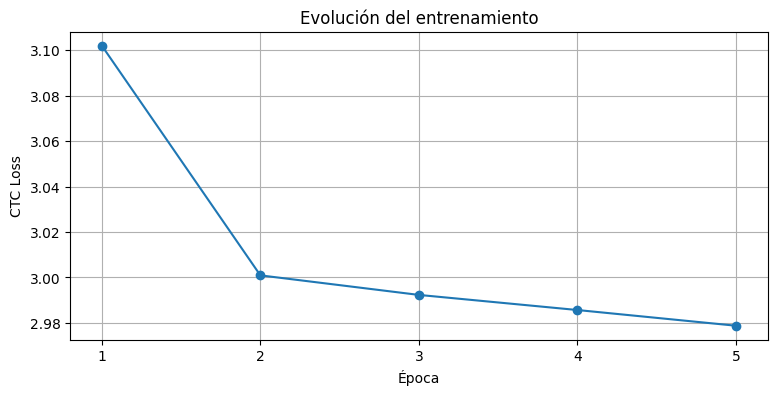

In [48]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim

EPOCHS = 5

ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

optimizer = optim.Adam(
    model.parameters(),
    lr=1e-4
)

history = []

for epoch in range(EPOCHS):

    model.train()
    total_loss = 0.0
    valid_batches = 0

    for batch_idx, batch in enumerate(train_loader):

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        optimizer.zero_grad()

        log_probs = model(videos, input_lengths)

        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            continue

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=5.0
        )

        optimizer.step()

        total_loss += loss.item()
        valid_batches += 1

    epoch_loss = total_loss / valid_batches
    history.append(epoch_loss)

    print(
        f"Época {epoch + 1}/{EPOCHS} | "
        f"Loss: {epoch_loss:.4f} | "
        f"Batches: {valid_batches}/{len(train_loader)}"
    )

plt.figure(figsize=(9, 4))
plt.plot(range(1, EPOCHS + 1), history, marker="o")
plt.xlabel("Época")
plt.ylabel("CTC Loss")
plt.title("Evolución del entrenamiento")
plt.xticks(range(1, EPOCHS + 1))
plt.grid(True)
plt.show()

## eval

In [63]:
def greedy_decode(log_probs, input_length):
    """
    Convierte las predicciones por timestep en una secuencia
    de caracteres usando greedy decoding + CTC collapse.
    """

    predictions = log_probs[:input_length].argmax(dim=-1).tolist()

    decoded = []
    previous = None

    for token in predictions:

        if token != previous and token != BLANK_IDX:
            decoded.append(idx_to_char[token])

        previous = token

    return "".join(decoded)


def edit_distance(reference, hypothesis):
    """
    Distancia de Levenshtein:
    sustituciones + inserciones + eliminaciones.
    """

    rows = len(reference) + 1
    cols = len(hypothesis) + 1

    dp = [[0] * cols for _ in range(rows)]

    for i in range(rows):
        dp[i][0] = i

    for j in range(cols):
        dp[0][j] = j

    for i in range(1, rows):
        for j in range(1, cols):

            if reference[i - 1] == hypothesis[j - 1]:
                cost = 0
            else:
                cost = 1

            dp[i][j] = min(
                dp[i - 1][j] + 1,       # Eliminación
                dp[i][j - 1] + 1,       # Inserción
                dp[i - 1][j - 1] + cost  # Sustitución
            )

    return dp[-1][-1]


def normalize_text(text):
    """
    Normalización mínima para comparar transcripciones.
    """

    return " ".join(text.lower().split())


In [64]:
ctc_loss = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

model.eval()

total_loss = 0.0
valid_batches = 0

total_char_errors = 0
total_chars = 0

total_word_errors = 0
total_words = 0

results = []


In [65]:

with torch.no_grad():

    for batch in test_loader:

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)

        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        # Forward
        log_probs = model(videos, input_lengths)

        # CTC Loss
        loss = ctc_loss(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if torch.isfinite(loss):
            total_loss += loss.item()
            valid_batches += 1

        # Decodificar cada video del batch
        target_offset = 0

        for i in range(len(input_lengths)):

            # Predicción
            prediction = greedy_decode(
                log_probs[:, i, :],
                input_lengths[i].item()
            )

            # Target correspondiente al video
            target_length = target_lengths[i].item()

            target = targets[
                target_offset:target_offset + target_length
            ].tolist()

            reference = "".join(
                idx_to_char[token]
                for token in target
            )

            target_offset += target_length

            # Normalización
            reference_norm = normalize_text(reference)
            prediction_norm = normalize_text(prediction)

            # CER
            char_errors = edit_distance(
                reference_norm,
                prediction_norm
            )

            total_char_errors += char_errors
            total_chars += len(reference_norm)

            # WER
            reference_words = reference_norm.split()
            prediction_words = prediction_norm.split()

            word_errors = edit_distance(
                reference_words,
                prediction_words
            )

            total_word_errors += word_errors
            total_words += len(reference_words)

            results.append({
                "reference": reference,
                "prediction": prediction,
                "char_errors": char_errors,
                "word_errors": word_errors
            })

In [66]:
test_loss = (
    total_loss / valid_batches
    if valid_batches > 0 else float("nan")
)

CER = (
    total_char_errors / total_chars
    if total_chars > 0 else float("nan")
)

WER = (
    total_word_errors / total_words
    if total_words > 0 else float("nan")
)

In [67]:
print("=" * 50)
print("RESULTADOS DE EVALUACIÓN")
print("=" * 50)

print(f"Clips evaluados: {len(results)}")
print(f"Test Loss:       {test_loss:.4f}")
print(f"CER:             {CER:.4f} ({CER * 100:.2f}%)")
print(f"WER:             {WER:.4f} ({WER * 100:.2f}%)")

print("\n" + "=" * 50)
print("EJEMPLOS DE PREDICCIONES")
print("=" * 50)

for i, result in enumerate(results[:10]):

    print(f"\nEjemplo {i + 1}")
    print("Real:      ", repr(result["reference"]))
    print("Predicción:", repr(result["prediction"]))
    print("Errores de caracteres:", result["char_errors"])
    print("Errores de palabras:  ", result["word_errors"])


print("\n" + "=" * 50)
print("DISTRIBUCIÓN DE PREDICCIONES")
print("=" * 50)

from collections import Counter

prediction_counts = Counter(
    result["prediction"] for result in results
)

for prediction, count in prediction_counts.most_common(15):
    print(f"{repr(prediction):30s} {count}")

RESULTADOS DE EVALUACIÓN
Clips evaluados: 357
Test Loss:       2.9128
CER:             0.9858 (98.58%)
WER:             1.0000 (100.00%)

EJEMPLOS DE PREDICCIONES

Ejemplo 1
Real:       ' La ficción es una herramienta poderosa'
Predicción: ' s'
Errores de caracteres: 37
Errores de palabras:   6

Ejemplo 2
Real:       ' Una tecnología blanda'
Predicción: ' s'
Errores de caracteres: 21
Errores de palabras:   3

Ejemplo 3
Real:       ' Las tecnologías blandas funcionan de la misma manera'
Predicción: ' s'
Errores de caracteres: 51
Errores de palabras:   8

Ejemplo 4
Real:       ' Cuando en las historias de la Biblia se nos cuenta que hay cosas que son correctas y hay cosas que son incorrectas'
Predicción: ' s'
Errores de caracteres: 113
Errores de palabras:   22

Ejemplo 5
Real:       ' que las cosas buenas son recompensadas y las cosas malas son castigadas'
Predicción: ' s'
Errores de caracteres: 70
Errores de palabras:   12

Ejemplo 6
Real:       ' la ficción lo que está haciendo es dar

distribución de caracteres por timestamp 

In [54]:
from collections import Counter
import torch

model.eval()

token_counts = Counter()
total_timesteps = 0
blank_probabilities = []
top_probabilities = []

with torch.no_grad():

    for batch in test_loader:

        videos = batch["videos"].to(DEVICE)
        input_lengths = batch["input_lengths"]

        log_probs = model(videos, input_lengths)
        probabilities = log_probs.exp()

        for i, length in enumerate(input_lengths):

            length = length.item()

            # Distribuciones de este video
            video_probs = probabilities[:length, i, :]

            # Clase más probable en cada timestep
            predictions = video_probs.argmax(dim=-1).tolist()

            token_counts.update(predictions)
            total_timesteps += length

            # Probabilidad media de blank
            blank_probabilities.extend(
                video_probs[:, BLANK_IDX].cpu().tolist()
            )

            # Confianza media de la clase más probable
            top_probabilities.extend(
                video_probs.max(dim=-1).values.cpu().tolist()
            )


print("TIMESTEPS ANALIZADOS:", total_timesteps)

print("\nDISTRIBUCIÓN DE CLASES PREDICHAS:")

for token, count in token_counts.most_common(15):

    if token == BLANK_IDX:
        character = "<BLANK>"
    else:
        character = repr(idx_to_char[token])

    percentage = 100 * count / total_timesteps

    print(f"{character:15s} {count:8d} ({percentage:.2f}%)")


print("\nPROBABILIDAD MEDIA DE BLANK:",
      sum(blank_probabilities) / len(blank_probabilities))

print("PROBABILIDAD MEDIA DE LA CLASE TOP:",
      sum(top_probabilities) / len(top_probabilities))

TIMESTEPS ANALIZADOS: 41412

DISTRIBUCIÓN DE CLASES PREDICHAS:
<BLANK>            40341 (97.41%)
' '                  714 (1.72%)
's'                  357 (0.86%)

PROBABILIDAD MEDIA DE BLANK: 0.4202343184221797
PROBABILIDAD MEDIA DE LA CLASE TOP: 0.4287462794193781


colapso en train?

In [55]:
from collections import Counter

def inspect_predictions(loader, name):

    model.eval()

    token_counts = Counter()
    decoded_counts = Counter()
    examples = []

    total_timesteps = 0

    with torch.no_grad():

        for batch in loader:

            videos = batch["videos"].to(DEVICE)
            input_lengths = batch["input_lengths"]

            log_probs = model(videos, input_lengths)

            for i, length in enumerate(input_lengths):

                length = length.item()

                video_probs = log_probs[:length, i, :]

                # Distribución de clases
                tokens = video_probs.argmax(dim=-1).tolist()

                token_counts.update(tokens)
                total_timesteps += length

                # Decodificación CTC
                prediction = greedy_decode(
                    log_probs[:, i, :],
                    length
                )

                decoded_counts[prediction] += 1

                if len(examples) < 10:
                    examples.append(prediction)

    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    print("Clips:", sum(decoded_counts.values()))
    print("Secuencias diferentes:", len(decoded_counts))

    print("\nClases por timestep:")

    for token, count in token_counts.most_common(10):

        character = (
            "<BLANK>"
            if token == BLANK_IDX
            else repr(idx_to_char[token])
        )

        percentage = 100 * count / total_timesteps

        print(f"{character:15s} {percentage:6.2f}%")

    print("\nPredicciones más frecuentes:")

    for prediction, count in decoded_counts.most_common(10):
        print(repr(prediction), ":", count)

    print("\nPrimeras 10 predicciones:")

    for prediction in examples:
        print(repr(prediction))


inspect_predictions(train_loader, "TRAIN")
inspect_predictions(test_loader, "TEST")


TRAIN
Clips: 947
Secuencias diferentes: 2

Clases por timestep:
<BLANK>          97.59%
' '               1.60%
's'               0.80%

Predicciones más frecuentes:
' s' : 946
' ' : 1

Primeras 10 predicciones:
' s'
' s'
' s'
' s'
' s'
' s'
' s'
' s'
' s'
' s'

TEST
Clips: 357
Secuencias diferentes: 1

Clases por timestep:
<BLANK>          97.41%
' '               1.72%
's'               0.86%

Predicciones más frecuentes:
' s' : 357

Primeras 10 predicciones:
' s'
' s'
' s'
' s'
' s'
' s'
' s'
' s'
' s'
' s'


# DIAGNOSTICO DE GRADIENTES

In [58]:

# Diagnóstico de gradientes: STCNN, BiGRU y clasificador

# Guardamos el modo actual y evitamos actualizar BatchNorm
was_training = model.training
model.train() # en eval chilla

# Tomamos un batch de entrenamiento
batch = next(iter(train_loader))

videos = batch["videos"].to(DEVICE)
targets = batch["targets"].to(DEVICE)
input_lengths = batch["input_lengths"]
target_lengths = batch["target_lengths"]

# Limpiamos gradientes anteriores
model.zero_grad(set_to_none=True)

# Forward + CTC loss
log_probs = model(videos, input_lengths)

criterion = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

loss = criterion(
    log_probs,
    targets,
    input_lengths,
    target_lengths
)

print(f"CTC Loss: {loss.item():.6f}")

# Backward: calcula gradientes, pero NO actualiza pesos
loss.backward()


def inspect_gradients(module, name):
    gradients = [
        p.grad.detach()
        for p in module.parameters()
        if p.grad is not None
    ]

    total_params = sum(1 for p in module.parameters())
    params_with_grad = len(gradients)

    if not gradients:
        print(f"\n{name}: SIN GRADIENTES")
        return

    total_norm = torch.sqrt(
        sum(g.pow(2).sum() for g in gradients)
    ).item()

    mean_abs = torch.cat([
        g.abs().flatten() for g in gradients
    ]).mean().item()

    max_abs = max(g.abs().max().item() for g in gradients)

    finite = all(torch.isfinite(g).all().item() for g in gradients)

    print(f"\n{name}")
    print(f"  Parámetros con gradiente: {params_with_grad}/{total_params}")
    print(f"  Norma global:             {total_norm:.8e}")
    print(f"  Media absoluta:           {mean_abs:.8e}")
    print(f"  Máximo absoluto:          {max_abs:.8e}")
    print(f"  Gradientes finitos:       {finite}")


inspect_gradients(model.visual_encoder, "STCNN")
inspect_gradients(model.temporal_encoder, "BiGRU")
inspect_gradients(model.classifier, "CLASIFICADOR")

# Restauramos el modo anterior
model.train(was_training)

# Limpiamos los gradientes de diagnóstico
model.zero_grad(set_to_none=True)


CTC Loss: 2.922693

STCNN
  Parámetros con gradiente: 6/6
  Norma global:             2.24501774e-01
  Media absoluta:           1.15271767e-04
  Máximo absoluto:          1.27952415e-02
  Gradientes finitos:       True

BiGRU
  Parámetros con gradiente: 16/16
  Norma global:             2.53621936e-01
  Media absoluta:           1.90296578e-05
  Máximo absoluto:          3.42281885e-03
  Gradientes finitos:       True

CLASIFICADOR
  Parámetros con gradiente: 2/2
  Norma global:             2.50346351e+00
  Media absoluta:           5.02487971e-03
  Máximo absoluto:          9.11367908e-02
  Gradientes finitos:       True


In [60]:

model.eval()

with torch.no_grad():
    log_probs = model(videos, input_lengths)
    probs = log_probs.exp()

    # Probabilidad media por clase
    mean_probs = probs.mean(dim=(0, 1))

    # Clases ganadoras por timestep
    predictions = log_probs.argmax(dim=-1)

    values, counts = torch.unique(
        predictions,
        return_counts=True
    )

    total = predictions.numel()

    print("PROBABILIDAD MEDIA POR CLASE:")
    top_values, top_indices = torch.topk(mean_probs, 10)

    for idx, value in zip(top_indices.tolist(), top_values.tolist()):
        char = idx_to_char[idx] if idx != BLANK_IDX else "<BLANK>"
        print(f"{repr(char):12s}: {value:.4f}")

    print("\nDISTRIBUCIÓN DE CLASES GANADORAS:")
    for idx, count in zip(values.tolist(), counts.tolist()):
        char = idx_to_char[idx] if idx != BLANK_IDX else "<BLANK>"
        print(f"{repr(char):12s}: {count:6d} ({100*count/total:.2f}%)")

model.train()


PROBABILIDAD MEDIA POR CLASE:
'<BLANK>'   : 0.2934
' '         : 0.0686
'e'         : 0.0423
'a'         : 0.0410
'o'         : 0.0332
's'         : 0.0317
'n'         : 0.0269
'r'         : 0.0235
'i'         : 0.0233
'd'         : 0.0203

DISTRIBUCIÓN DE CLASES GANADORAS:
'<BLANK>'   :    312 (65.55%)
' '         :      4 (0.84%)
'D'         :    158 (33.19%)
's'         :      2 (0.42%)


LipReadingModel(
  (visual_encoder): STCNN(
    (block1): Sequential(
      (0): Conv3d(3, 32, kernel_size=(3, 5, 5), stride=(1, 2, 2), padding=(1, 2, 2))
      (1): ReLU()
      (2): MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2), padding=0, dilation=1, ceil_mode=False)
      (3): Dropout3d(p=0.5, inplace=False)
    )
    (block2): Sequential(
      (0): Conv3d(32, 64, kernel_size=(3, 5, 5), stride=(1, 1, 1), padding=(1, 2, 2))
      (1): ReLU()
      (2): MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2), padding=0, dilation=1, ceil_mode=False)
      (3): Dropout3d(p=0.5, inplace=False)
    )
    (block3): Sequential(
      (0): Conv3d(64, 96, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
      (1): ReLU()
      (2): MaxPool3d(kernel_size=(1, 2, 2), stride=(1, 2, 2), padding=0, dilation=1, ceil_mode=False)
      (3): Dropout3d(p=0.5, inplace=False)
    )
  )
  (temporal_encoder): TemporalEncoder(
    (rnn): GRU(3456, 256, num_layers=2, bidirectional=True)
  )
  (clas

In [70]:

from collections import Counter

def compare_split(name, loader):
    model.eval()
    refs, hyps = [], []

    with torch.no_grad():
        for batch in loader:
            videos = batch["videos"].to(DEVICE)
            input_lengths = batch["input_lengths"]

            log_probs = model(videos, input_lengths)

            for i, length in enumerate(input_lengths.tolist()):
                hyp = greedy_decode(log_probs[:, i, :], length)
                hyps.append(hyp)

            refs.extend(batch["texts"])

    char_errors = sum(
        edit_distance(ref, hyp)
        for ref, hyp in zip(refs, hyps)
    )
    total_chars = sum(len(ref) for ref in refs)

    word_errors = sum(
        edit_distance(ref.split(), hyp.split())
        for ref, hyp in zip(refs, hyps)
    )
    total_words = sum(len(ref.split()) for ref in refs)

    cer = char_errors / max(total_chars, 1)
    wer = word_errors / max(total_words, 1)

    print(f"\n{'=' * 45}")
    print(name)
    print(f"{'=' * 45}")
    print(f"Clips: {len(refs)}")
    print(f"CER: {cer:.4f} ({cer*100:.2f}%)")
    print(f"WER: {wer:.4f} ({wer*100:.2f}%)")
    print(f"Secuencias diferentes: {len(set(hyps))}")

    print("\nPredicciones más frecuentes:")
    for prediction, count in Counter(hyps).most_common(5):
        print(f"  {repr(prediction)}: {count}")

    print("\nPrimeros 5 ejemplos:")
    for ref, hyp in list(zip(refs, hyps))[:5]:
        print(f"  REAL: {repr(ref)}")
        print(f"  PRED: {repr(hyp)}")


compare_split("TRAIN", train_loader)
compare_split("TEST", test_loader)



TRAIN
Clips: 947
CER: 0.9727 (97.27%)
WER: 1.0000 (100.00%)
Secuencias diferentes: 2

Predicciones más frecuentes:
  ' s': 946
  ' ': 1

Primeros 5 ejemplos:
  REAL: ' que realmente no nos ayuda a entender y a abordar los grandes retos de la vida'
  PRED: ' s'
  REAL: ' y lo repito una y otra vez una y otra vez'
  PRED: ' s'
  REAL: ' es un guatemalteco nacido en 1700 él es uno de los poetas neoresnacentistas'
  PRED: ' s'
  REAL: ' La explotación de la humanidad a lo largo de la historia ha tomado diferentes formas pero en esencia es lo mismo'
  PRED: ' s'
  REAL: ' Será que este proyecto calza o entra dentro de la Argentina'
  PRED: ' s'

TEST
Clips: 357
CER: 0.9716 (97.16%)
WER: 1.0000 (100.00%)
Secuencias diferentes: 1

Predicciones más frecuentes:
  ' s': 357

Primeros 5 ejemplos:
  REAL: ' La ficción es una herramienta poderosa'
  PRED: ' s'
  REAL: ' Una tecnología blanda'
  PRED: ' s'
  REAL: ' Las tecnologías blandas funcionan de la misma manera'
  PRED: ' s'
  REAL: ' Cuando

# OVERFIT TEST

In [72]:

# ==========================================
# OVERFIT TEST - Selección de 8 clips
# ==========================================

N_OVERFIT = 8

# Longitud mínima que necesita CTC:
# caracteres + repeticiones consecutivas
def min_ctc_frames(text):
    return len(text) + sum(
        a == b for a, b in zip(text, text[1:])
    )

overfit_df = clips_df.copy().reset_index(drop=True)

# Usamos los frames de metadata
overfit_df["min_ctc_frames"] = overfit_df["label"].astype(str).map(
    min_ctc_frames
)

overfit_df["ctc_ratio"] = (
    overfit_df["frames"] / overfit_df["min_ctc_frames"]
)

# Filtramos clips con margen temporal razonable
pool = overfit_df[
    (overfit_df["frames"] >= overfit_df["min_ctc_frames"]) &
    (overfit_df["ctc_ratio"] >= 1.3)
]

if len(pool) < N_OVERFIT:
    raise ValueError(
        f"Solo hay {len(pool)} clips aptos para seleccionar {N_OVERFIT}."
    )

# Elegimos 8 clips cortos con margen CTC suficiente
overfit_df = (
    pool.sort_values("frames")
    .head(N_OVERFIT)
    .reset_index(drop=True)
)

print(f"Clips seleccionados: {len(overfit_df)}")
print()

for i, row in overfit_df.iterrows():
    print(f"Clip {i+1}")
    print(f"  Video: {row['video_id']}")
    print(f"  Frames: {row['frames']}")
    print(f"  Caracteres: {len(row['label'])}")
    print(f"  Mínimo CTC: {row['min_ctc_frames']}")
    print(f"  Ratio: {row['ctc_ratio']:.2f}")
    print(f"  Texto: {repr(row['label'])}")
    print()


Clips seleccionados: 8

Clip 1
  Video: RhfM5LropRw
  Frames: 40
  Caracteres: 26
  Mínimo CTC: 26
  Ratio: 1.54
  Texto: ' Justamente hace dos meses'

Clip 2
  Video: of6m8w8Vgr4
  Frames: 40
  Caracteres: 25
  Mínimo CTC: 25
  Ratio: 1.60
  Texto: ' Gio admiro mucho tu vida'

Clip 3
  Video: of6m8w8Vgr4
  Frames: 40
  Caracteres: 29
  Mínimo CTC: 29
  Ratio: 1.38
  Texto: ' Algún día quiero ser como tú'

Clip 4
  Video: oL5ov6pUaCE
  Frames: 40
  Caracteres: 16
  Mínimo CTC: 16
  Ratio: 2.50
  Texto: ' pude observarme'

Clip 5
  Video: hCA0t7WsSvk
  Frames: 40
  Caracteres: 22
  Mínimo CTC: 23
  Ratio: 1.74
  Texto: ' Y cambias el rollo de'

Clip 6
  Video: KV4B34JUE9g
  Frames: 41
  Caracteres: 24
  Mínimo CTC: 24
  Ratio: 1.71
  Texto: ' gastos que el cual está'

Clip 7
  Video: NNPH7KWjrrs
  Frames: 41
  Caracteres: 20
  Mínimo CTC: 20
  Ratio: 2.05
  Texto: ' una escucha un oído'

Clip 8
  Video: hCA0t7WsSvk
  Frames: 41
  Caracteres: 30
  Mínimo CTC: 31
  Ratio: 1.32
  Texto: ' 

In [73]:

# ==========================================
# OVERFIT TEST - Dataset en memoria
# ==========================================

from torch.utils.data import Dataset, DataLoader

class InMemoryDataset(Dataset):
    def __init__(self, samples):
        self.samples = samples

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        return self.samples[index]


# Decodificar los 8 clips
base_dataset = ViSpeRDataset(overfit_df)

cached_samples = [
    base_dataset[i]
    for i in range(len(base_dataset))
]

# Dataset en memoria
overfit_dataset = InMemoryDataset(cached_samples)

# Loader de entrenamiento
overfit_loader = DataLoader(
    overfit_dataset,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

# Loader de evaluación: mismo conjunto, sin mezclar
overfit_eval_loader = DataLoader(
    overfit_dataset,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

print("Dataset preparado")
print("Muestras:", len(overfit_dataset))
print("Batches de entrenamiento:", len(overfit_loader))
print("Batches de evaluación:", len(overfit_eval_loader))

# Verificar un batch
sample_batch = next(iter(overfit_eval_loader))

print("\nDimensiones del primer batch:")
print("Videos:", sample_batch["videos"].shape)
print("Targets:", sample_batch["targets"].shape)
print("Input lengths:", sample_batch["input_lengths"].tolist())
print("Target lengths:", sample_batch["target_lengths"].tolist())

print("\nTextos:")
for text in sample_batch["texts"]:
    print(repr(text))


Dataset preparado
Muestras: 8
Batches de entrenamiento: 2
Batches de evaluación: 2

Dimensiones del primer batch:
Videos: torch.Size([4, 40, 3, 96, 96])
Targets: torch.Size([96])
Input lengths: [40, 40, 40, 40]
Target lengths: [26, 25, 29, 16]

Textos:
' Justamente hace dos meses'
' Gio admiro mucho tu vida'
' Algún día quiero ser como tú'
' pude observarme'


In [74]:

# ==========================================
# OVERFIT TEST - Inicialización del modelo
# ==========================================

torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

of_model = LipReadingModel(
    in_channels=INPUT_CHANNELS,
    vocab_size=VOCAB_SIZE,
    hidden_size=256,
    rnn_type="gru"
).to(DEVICE)

# Desactivar dropout para facilitar la memorización
for module in of_model.modules():
    if isinstance(module, (nn.Dropout, nn.Dropout2d, nn.Dropout3d)):
        module.p = 0.0

of_criterion = nn.CTCLoss(
    blank=BLANK_IDX,
    reduction="mean",
    zero_infinity=True
)

OF_LR = 3e-4

of_optimizer = torch.optim.Adam(
    of_model.parameters(),
    lr=OF_LR
)

print("Modelo de overfit inicializado")
print("Dispositivo:", DEVICE)
print("Parámetros:", sum(p.numel() for p in of_model.parameters()))
print("Learning rate:", OF_LR)
print("Dropout: 0.0")
print("Optimizador: Adam")


Modelo de overfit inicializado
Dispositivo: cuda
Parámetros: 7250727
Learning rate: 0.0003
Dropout: 0.0
Optimizador: Adam


In [75]:

# ==========================================
# OVERFIT TEST - Entrenamiento
# ==========================================

import time

OF_EPOCHS = 400
EVAL_EVERY = 10
CLIP_GRAD = 5.0

of_history = []

for epoch in range(1, OF_EPOCHS + 1):

    of_model.train()
    epoch_loss = 0.0

    for batch in overfit_loader:

        videos = batch["videos"].to(DEVICE)
        targets = batch["targets"].to(DEVICE)
        input_lengths = batch["input_lengths"]
        target_lengths = batch["target_lengths"]

        of_optimizer.zero_grad(set_to_none=True)

        log_probs = of_model(videos, input_lengths)

        loss = of_criterion(
            log_probs,
            targets,
            input_lengths,
            target_lengths
        )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Loss no finita en época {epoch}: {loss.item()}"
            )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            of_model.parameters(),
            max_norm=CLIP_GRAD
        )

        of_optimizer.step()

        epoch_loss += loss.item()

    epoch_loss /= len(overfit_loader)

    if epoch == 1 or epoch % EVAL_EVERY == 0:

        of_model.eval()

        refs = []
        hyps = []

        with torch.no_grad():
            for batch in overfit_eval_loader:

                videos = batch["videos"].to(DEVICE)
                input_lengths = batch["input_lengths"]

                log_probs = of_model(videos, input_lengths)

                refs.extend(batch["texts"])

                for i, length in enumerate(input_lengths.tolist()):
                    hyp = greedy_decode(log_probs[:, i, :], length)
                    hyps.append(hyp)

        char_errors = sum(
            edit_distance(ref, hyp)
            for ref, hyp in zip(refs, hyps)
        )

        total_chars = sum(len(ref) for ref in refs)
        cer = char_errors / max(total_chars, 1)

        word_errors = sum(
            edit_distance(ref.split(), hyp.split())
            for ref, hyp in zip(refs, hyps)
        )

        total_words = sum(len(ref.split()) for ref in refs)
        wer = word_errors / max(total_words, 1)

        of_history.append({
            "epoch": epoch,
            "loss": epoch_loss,
            "cer": cer,
            "wer": wer
        })

        print(
            f"Época {epoch:3d} | "
            f"Loss: {epoch_loss:.4f} | "
            f"CER: {cer:.4f} | "
            f"WER: {wer:.4f}"
        )

        if cer == 0.0:
            print("\n¡Overfit conseguido! CER = 0")
            break


Época   1 | Loss: 5.8347 | CER: 1.0000 | WER: 1.0000
Época  10 | Loss: 2.9261 | CER: 0.9583 | WER: 1.0000
Época  20 | Loss: 2.7931 | CER: 0.9583 | WER: 1.0000
Época  30 | Loss: 2.6649 | CER: 0.9375 | WER: 1.0000
Época  40 | Loss: 2.5417 | CER: 0.9271 | WER: 1.0000
Época  50 | Loss: 2.4069 | CER: 0.9219 | WER: 1.0000
Época  60 | Loss: 2.2691 | CER: 0.9062 | WER: 1.0000
Época  70 | Loss: 2.1451 | CER: 0.8802 | WER: 1.0000
Época  80 | Loss: 2.0065 | CER: 0.8333 | WER: 1.0000
Época  90 | Loss: 1.8512 | CER: 0.7969 | WER: 1.0000
Época 100 | Loss: 1.7397 | CER: 0.7552 | WER: 0.9744
Época 110 | Loss: 1.5809 | CER: 0.7083 | WER: 0.9231
Época 120 | Loss: 1.4072 | CER: 0.6667 | WER: 0.8974
Época 130 | Loss: 1.3551 | CER: 0.6302 | WER: 0.8462
Época 140 | Loss: 1.1599 | CER: 0.5677 | WER: 0.8974
Época 150 | Loss: 1.0616 | CER: 0.4896 | WER: 0.8974
Época 160 | Loss: 0.9118 | CER: 0.4167 | WER: 0.7949
Época 170 | Loss: 0.8102 | CER: 0.3385 | WER: 0.7436
Época 180 | Loss: 0.6658 | CER: 0.2604 | WER: 

In [76]:

of_model.eval()

with torch.no_grad():
    for batch in overfit_eval_loader:
        videos = batch["videos"].to(DEVICE)
        input_lengths = batch["input_lengths"]

        log_probs = of_model(videos, input_lengths)

        for i, length in enumerate(input_lengths.tolist()):
            reference = batch["texts"][i]
            prediction = greedy_decode(
                log_probs[:, i, :],
                length
            )

            print("REFERENCIA:", repr(reference))
            print("PREDICCIÓN:", repr(prediction))
            print("COINCIDEN:", reference == prediction)
            print("-" * 70)


REFERENCIA: ' Justamente hace dos meses'
PREDICCIÓN: ' Justamente hace dos meses'
COINCIDEN: True
----------------------------------------------------------------------
REFERENCIA: ' Gio admiro mucho tu vida'
PREDICCIÓN: ' Gio admiro mucho tu vida'
COINCIDEN: True
----------------------------------------------------------------------
REFERENCIA: ' Algún día quiero ser como tú'
PREDICCIÓN: ' Algún día quiero ser como tú'
COINCIDEN: True
----------------------------------------------------------------------
REFERENCIA: ' pude observarme'
PREDICCIÓN: ' pude observarme'
COINCIDEN: True
----------------------------------------------------------------------
REFERENCIA: ' Y cambias el rollo de'
PREDICCIÓN: ' Y cambias el rollo de'
COINCIDEN: True
----------------------------------------------------------------------
REFERENCIA: ' gastos que el cual está'
PREDICCIÓN: ' gastos que el cual está'
COINCIDEN: True
----------------------------------------------------------------------
REFERENCIA: ' 